# Minh — Giai đoạn 1: Khảo sát RGB → Binary

Notebook trình bày trực quan 4 phương pháp chuyển ảnh màu PCB sang nhị phân:

1. `gray_otsu` — Gray → Gaussian 3×3 → Otsu
2. `lab_b_otsu` — kênh b* của Lab → Otsu
3. `lab_a_otsu` — kênh a* của Lab → Otsu
4. `clahe_otsu` — Gray → CLAHE → Gaussian 3×3 → Otsu

**Nguyên tắc**

- Logic thuật toán và cách đo chỉ số lấy từ `experiments/exp_rgb2binary.py` (một nguồn duy nhất).
- Notebook chỉ **đọc** `data/PKU-Market-PCB/`, không sửa manifest/labels.
- Số liệu chính thức lấy từ `experiments/rgb2binary_results.csv`, không lấy từ output cell.
- Trước khi lấy số hoặc chụp ảnh báo cáo: **Kernel → Restart & Run All**.


In [2]:
from pathlib import Path
import csv
import os
import sys

# Tìm project root (thư mục chứa dataset_utils.py) để notebook chạy được từ mọi nơi.
PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "dataset_utils.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "experiments"))

import cv2
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display

from dataset_utils import find_pairs, load_image
from exp_rgb2binary import (
    METHODS,
    evaluate_pair,
    summarize,
    print_summary,
    plot_metrics,
)

plt.rcParams["figure.dpi"] = 110
print("Project root :", PROJECT_ROOT)
print("Phương pháp  :", ", ".join(METHODS))


Project root : e:\BtapThucHanh\ProjectPCB
Phương pháp  : gray_otsu, lab_b_otsu, lab_a_otsu, clahe_otsu


## 1. Nạp dữ liệu

Đọc `pairs_manifest.csv` và lấy một cặp mẫu để xem cấu trúc dữ liệu.


In [3]:
pairs = find_pairs(str(PROJECT_ROOT / "data"))
print(f"Tìm thấy {len(pairs)} cặp ảnh")

sample = pairs[0]
img_template = load_image(sample["template_path"])
img_test = load_image(sample["test_path"])

print("pair_id    :", sample["pair_id"])
print("class_name :", sample["class_name"])
print("board_id   :", sample["board_id"])
print("template   :", img_template.shape)
print("test       :", img_test.shape)


Tìm thấy 693 cặp ảnh
pair_id    : 01_missing_hole_01
class_name : Missing_hole
board_id   : 01
template   : (1586, 3034, 3)
test       : (1586, 3034, 3)


### Hiển thị cặp ảnh mẫu


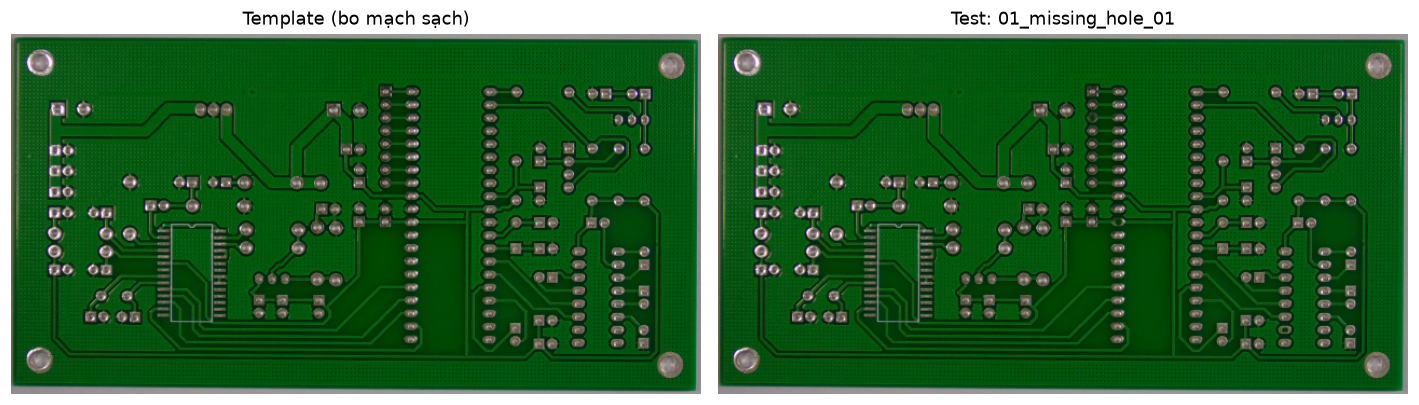

In [4]:
def to_display(image, max_width: int = 640):
    """Chuyển BGR/gray sang RGB và thu nhỏ để hiển thị trong notebook."""
    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    else:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    if width > max_width:
        scale = max_width / width
        image = cv2.resize(
            image,
            (max_width, int(height * scale)),
            interpolation=cv2.INTER_AREA,
        )
    return image


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].imshow(to_display(img_template))
axes[0].set_title("Template (bo mạch sạch)")
axes[0].axis("off")
axes[1].imshow(to_display(img_test))
axes[1].set_title(f"Test: {sample['pair_id']}")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 2. Trực quan 4 phương pháp trên cùng một ảnh

Mỗi hàng: ảnh gốc → kênh trung gian dùng cho Otsu → mask nhị phân cuối cùng.

- `lab_b_otsu` và `lab_a_otsu` dùng trực tiếp kênh màu Lab.
- `gray_otsu` và `clahe_otsu` dùng ảnh xám; CLAHE kéo giãn tương phản cục bộ.


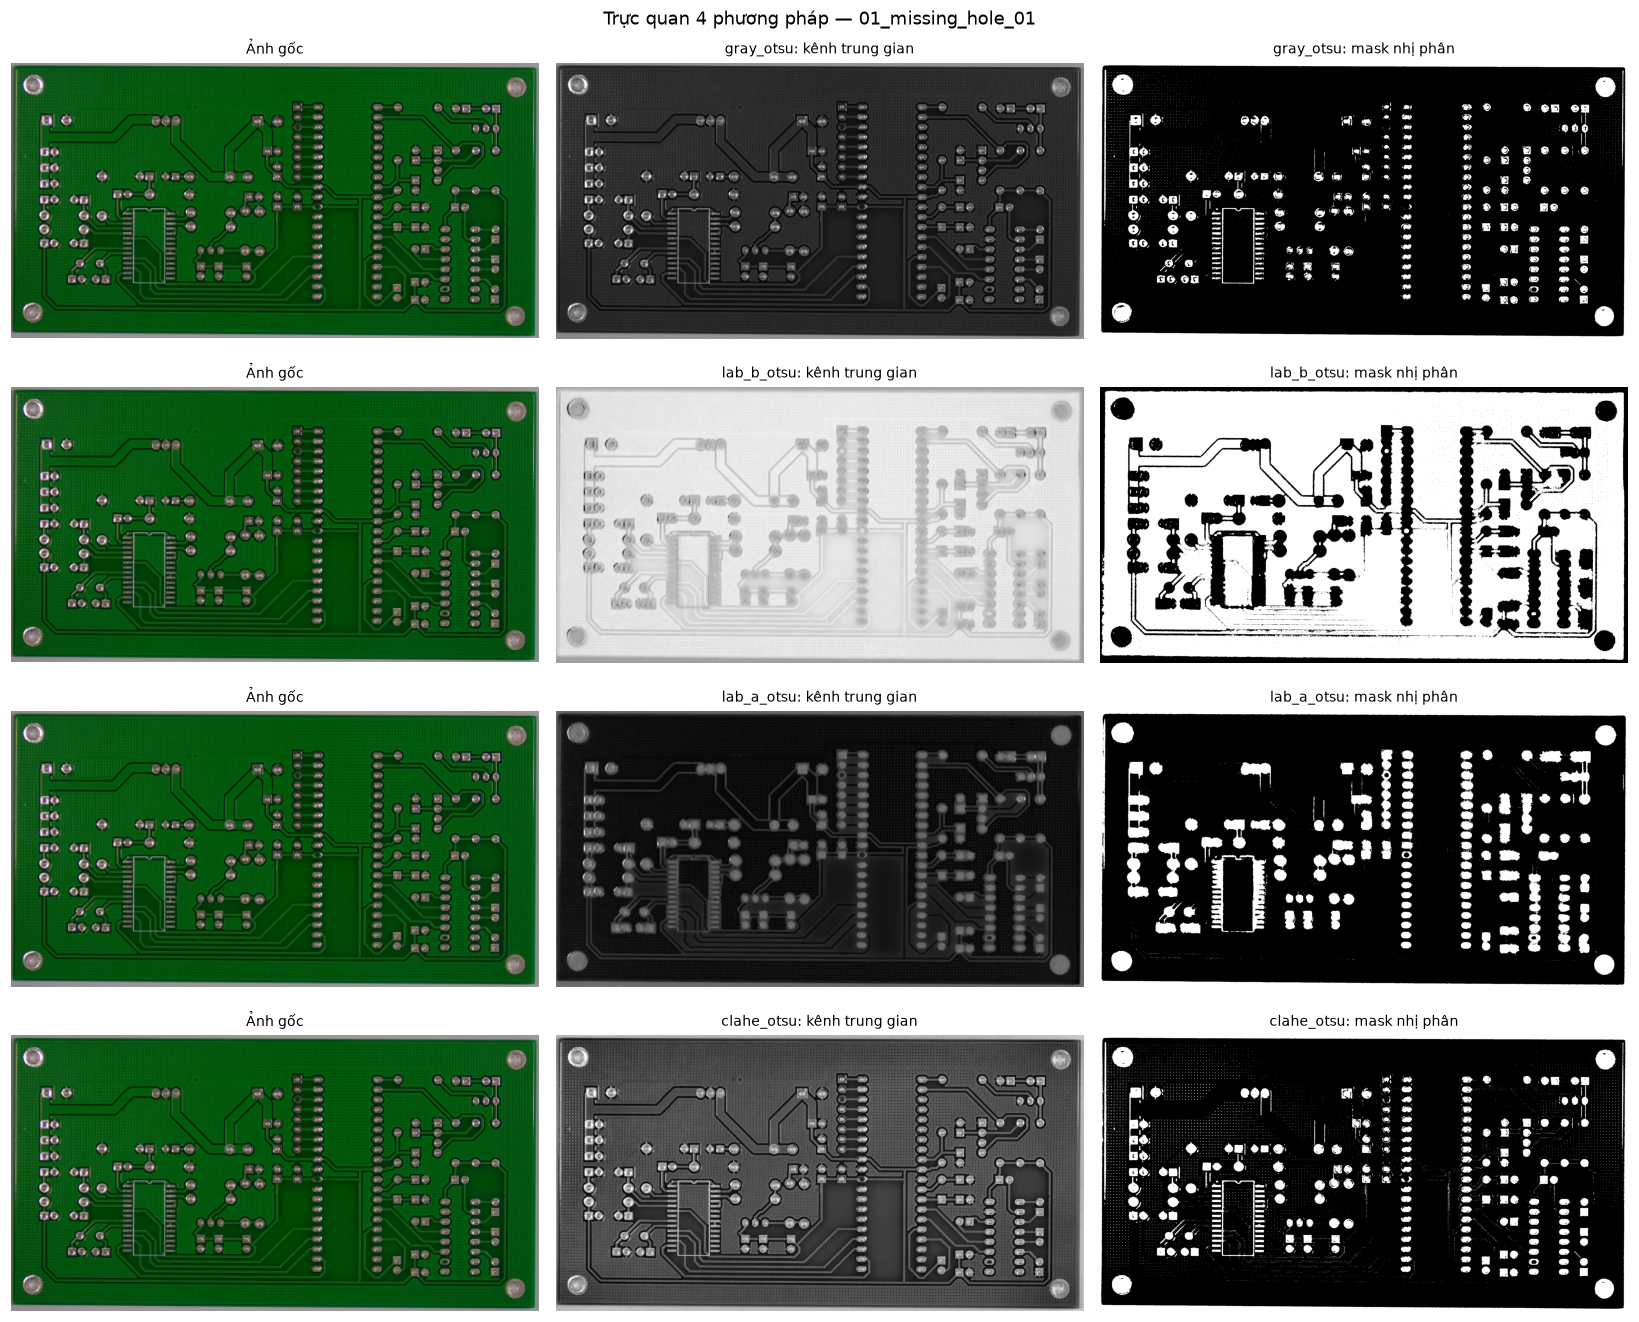

In [5]:
fig, axes = plt.subplots(
    len(METHODS), 3, figsize=(15, 3.1 * len(METHODS)), squeeze=False
)

for row, (name, method) in enumerate(METHODS.items()):
    mask, channel = method(img_test)
    panels = [
        (to_display(img_test), "Ảnh gốc", None),
        (channel, f"{name}: kênh trung gian", "gray"),
        (mask, f"{name}: mask nhị phân", "gray"),
    ]
    for col, (image, title, cmap) in enumerate(panels):
        axes[row, col].imshow(image, cmap=cmap)
        axes[row, col].set_title(title, fontsize=9)
        axes[row, col].axis("off")

fig.suptitle(f"Trực quan 4 phương pháp — {sample['pair_id']}", fontsize=12)
plt.tight_layout()
plt.show()


## 3. Đo chỉ số trên 5 cặp đầu (demo)

Cùng một hàm `evaluate_pair` như script CLI: đo thời gian trung vị, độ tách lớp Otsu, tỷ lệ foreground, bảo toàn biên cạnh và độ bền khi lệch sáng.


In [6]:
DEMO_LIMIT = 5
demo_pairs = pairs[:DEMO_LIMIT]
demo_rows = []

for index, pair in enumerate(demo_pairs, start=1):
    test_image = load_image(pair["test_path"])
    for method_name, method in METHODS.items():
        metrics = evaluate_pair(test_image, method, repeats=3)
        demo_rows.append(
            {
                "pair": pair["pair_id"],
                "method": method_name,
                **{key: round(value, 6) for key, value in metrics.items()},
            }
        )
    print(f"[{index}/{len(demo_pairs)}] {pair['pair_id']}")

print_summary(summarize(demo_rows), len(demo_pairs))


[1/5] 01_missing_hole_01
[2/5] 01_missing_hole_02
[3/5] 01_missing_hole_03
[4/5] 01_missing_hole_04
[5/5] 01_missing_hole_05

Đã khảo sát 5 cặp ảnh.
--------------------------------------------------------------------------------------------
Phương pháp    |  Time (ms) |  Otsu eta |  Foreground % |  Edge ret. |  Illum IoU
--------------------------------------------------------------------------------------------
gray_otsu      |      6.775 |    0.7247 |        11.00% |     0.2488 |     0.8044
lab_b_otsu     |     12.620 |    0.7670 |        75.21% |     0.1727 |     0.9531
lab_a_otsu     |     12.486 |    0.7860 |        16.87% |     0.0983 |     0.9031
clahe_otsu     |     11.133 |    0.6388 |        13.65% |     0.3600 |     0.8682
--------------------------------------------------------------------------------------------


## 4. Chạy full 693 cặp (tùy chọn)

Mặc định **tắt** để tránh ghi đè số liệu chính thức. Nếu bật, kết quả ghi vào `experiments/notebook_rgb2binary/` chứ không ghi vào `experiments/rgb2binary_results.csv`.


In [ ]:
RUN_FULL = False
FULL_REPEATS = 3
NOTEBOOK_OUTPUT = PROJECT_ROOT / "experiments" / "notebook_rgb2binary"

if not RUN_FULL:
    print("RUN_FULL = False — bỏ qua. Đổi thành True nếu muốn chạy đủ 693 cặp.")
else:
    full_rows = []
    for index, pair in enumerate(pairs, start=1):
        test_image = load_image(pair["test_path"])
        for method_name, method in METHODS.items():
            metrics = evaluate_pair(test_image, method, repeats=FULL_REPEATS)
            full_rows.append(
                {
                    "pair": pair["pair_id"],
                    "method": method_name,
                    **{key: round(value, 6) for key, value in metrics.items()},
                }
            )
        if index % 25 == 0 or index == len(pairs):
            print(f"[{index}/{len(pairs)}] ...")

    NOTEBOOK_OUTPUT.mkdir(parents=True, exist_ok=True)
    notebook_csv = NOTEBOOK_OUTPUT / "rgb2binary_results.csv"
    fieldnames = [
        "pair",
        "method",
        "time_ms",
        "otsu_eta",
        "foreground_ratio",
        "edge_retention",
        "illum_iou",
    ]
    with notebook_csv.open("w", newline="", encoding="utf-8-sig") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(full_rows)
    print("Đã ghi:", notebook_csv)


## 5. Đọc số liệu chính thức (693 cặp) và vẽ biểu đồ

Đọc `experiments/rgb2binary_results.csv` — file đã dùng để điền `PROGRESS_REPORT.md`.


In [ ]:
official_csv = PROJECT_ROOT / "experiments" / "rgb2binary_results.csv"
with official_csv.open("r", encoding="utf-8-sig", newline="") as handle:
    official_rows = list(csv.DictReader(handle))

print(f"Đọc {len(official_rows)} dòng từ {official_csv.name}")
official_summary = summarize(official_rows)
print_summary(official_summary, len({row["pair"] for row in official_rows}))


In [ ]:
import tempfile

chart_path = Path(tempfile.gettempdir()) / "rgb2binary_metrics_notebook.png"
plot_metrics(official_summary, chart_path)
display(Image(filename=str(chart_path)))


## 6. Trực quan mask trên 3 cặp đầu

Dùng cùng định dạng với `experiments/charts/rgb2binary_visual.png`.


In [ ]:
VISUAL_PAIRS = 3
selected_pairs = pairs[:VISUAL_PAIRS]
method_names = list(METHODS)

fig, axes = plt.subplots(
    len(selected_pairs),
    1 + len(method_names),
    figsize=(3.4 * (1 + len(method_names)), 2.8 * len(selected_pairs)),
    squeeze=False,
)

for row, pair in enumerate(selected_pairs):
    test_image = load_image(pair["test_path"])
    axes[row, 0].imshow(to_display(test_image, max_width=420))
    axes[row, 0].set_title(pair["pair_id"], fontsize=9)
    axes[row, 0].axis("off")

    for col, method_name in enumerate(method_names, start=1):
        mask, _ = METHODS[method_name](test_image)
        axes[row, col].imshow(mask, cmap="gray")
        axes[row, col].set_title(method_name, fontsize=9)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


## 7. Kết luận tự động từ CSV

Các dòng dưới đây chỉ tóm tắt lại số liệu trong CSV; kết luận đầy đủ nằm ở `PROGRESS_REPORT.md` Mục 3.3.


In [ ]:
best_edge = max(
    official_summary,
    key=lambda name: official_summary[name]["edge_retention"][0],
)
fastest = min(
    official_summary,
    key=lambda name: official_summary[name]["time_ms"][0],
)
best_illum = max(
    official_summary,
    key=lambda name: official_summary[name]["illum_iou"][0],
)

print(
    "Bảo toàn biên cạnh tốt nhất :",
    best_edge,
    round(official_summary[best_edge]["edge_retention"][0], 3),
)
print(
    "Nhanh nhất                  :",
    fastest,
    round(official_summary[fastest]["time_ms"][0], 2),
    "ms",
)
print(
    "Bền với lệch sáng nhất      :",
    best_illum,
    round(official_summary[best_illum]["illum_iou"][0], 3),
)


---

**Ghi chú khi commit**

- Notebook này không được import bởi `main.py` hay pipeline, nên không ảnh hưởng hệ thống nhóm.
- Trước khi commit, xóa output để tránh phình repo:

```powershell
jupyter nbconvert --clear-output --inplace experiments/notebooks/rgb2binary.ipynb
```

- Không sửa `exp_rgb2binary.py`, `data/`, `results/`, `crops/` từ notebook.
